# just_tx vs just_tx_hal：丢包扫速与 ~5% 工作点 RTT

同一块 ESP32-C3、同一 AP、同一台 TR3000。HAL / XDP 用**同一组** TR3000 发包速率扫丢包与回包 PPS，再在各自「丢包≈5%」的最大速率上测 RTT。

| 臂 | 固件 / 冷表 | 回发路径 |
|---|---|---|
| **HAL** | `just_tx_hal` | 应用层 UDP:8080 原载荷回发 |
| **XDP** | `just_drop` 固件 + 冷表 `just_tx.elf` | Wi-Fi 入口 MAC 交换后 `XDP_TX` |

工作点：扫速各点取试次中位丢包；落在 4%–7% 内取最大 `target_pps`，否则取最接近 5% 的点。

数据：`formal.just_tx_rtt_*`，`source_note = xpost-test just-tx-rtt`，`phase` = `sweep` | `operating`。

**复现**（cwd = `xpost/`）：

```bash
cargo xtask agent --listen 0.0.0.0:9240 --no-monitor
```

TR3000：

```bash
XPOST_AGENT_ENDPOINT=192.168.110.96:9240 ./xpost-test just-tx-rtt
```

本笔记只读库（`.env` 设 `PGSCHEMA=formal`）。下方先画扫速 / RTT，再画满速处理 PPS。


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from utils.db import dsn_summary
from utils.experiment import figure_tx_rtt_loss_vs_rate, load_just_tx_rtt_runs

SOURCE_NOTE = "xpost-test just-tx-rtt"
plt.ioff()
plt.close("all")
print(dsn_summary())

sweep = load_just_tx_rtt_runs(run_kind="pilot", source_note=SOURCE_NOTE, phase="sweep")
assert len(sweep), "无 sweep 行：先跑 ./xpost-test just-tx-rtt（勿加 --no-pg）"

rates = sorted(sweep["target_pps"].unique())


def _med_loss(variant: str, rate: float):
    sub = sweep[(sweep["variant"] == variant) & (np.isclose(sweep["target_pps"], rate))]
    if sub.empty:
        return None
    return float(sub["loss_rate"].median())


hal_loss = [_med_loss("hal", r) for r in rates]
xdp_loss = [_med_loss("xdp", r) for r in rates]
print("rates=", [int(r) for r in rates])
print("hal_loss%=", [None if v is None else round(100 * v, 2) for v in hal_loss])
print("xdp_loss%=", [None if v is None else round(100 * v, 2) for v in xdp_loss])

fig, _ = figure_tx_rtt_loss_vs_rate(
    rates_pps=rates,
    hal_loss=hal_loss,
    xdp_loss=xdp_loss,
    title="Loss vs send rate",
)
display(fig)
plt.close(fig)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from utils.db import dsn_summary
from utils.experiment import (
    figure_tx_rtt_boxplot,
    load_just_tx_rtt_runs,
    load_just_tx_rtt_samples,
)

SOURCE_NOTE = "xpost-test just-tx-rtt"
LOSS_LO, LOSS_HI, TARGET = 0.04, 0.07, 0.05
plt.ioff()
plt.close("all")
print(dsn_summary())

sweep = load_just_tx_rtt_runs(run_kind="pilot", source_note=SOURCE_NOTE, phase="sweep")
ops = load_just_tx_rtt_runs(run_kind="pilot", source_note=SOURCE_NOTE, phase="operating")
assert len(ops), "无 operating 行：先跑 ./xpost-test just-tx-rtt"


def pick_op(variant: str):
    sub = sweep[sweep["variant"] == variant]
    rows = []
    for rate, g in sub.groupby("target_pps"):
        rows.append((float(rate), float(g["loss_rate"].median())))
    in_band = [r for r in rows if LOSS_LO <= r[1] <= LOSS_HI]
    if in_band:
        rate, loss = max(in_band, key=lambda x: x[0])
    else:
        rate, loss = min(rows, key=lambda x: abs(x[1] - TARGET))
    return rate, loss


def rtts_for(variant: str):
    sub = ops[ops["variant"] == variant]
    samples = load_just_tx_rtt_samples(sub["run_id"].tolist())
    ok = samples[samples["ok"] & samples["rtt_ms"].notna()]
    return [float(x) for x in ok["rtt_ms"].tolist()]


hal_rate, hal_loss = pick_op("hal")
xdp_rate, xdp_loss = pick_op("xdp")
hal_rtts = rtts_for("hal")
xdp_rtts = rtts_for("xdp")
hal_label = f"HAL · {hal_rate:.0f} pps · loss {100 * hal_loss:.1f}%"
xdp_label = f"XDP · {xdp_rate:.0f} pps · loss {100 * xdp_loss:.1f}%"
print(hal_label, f"n_rtt={len(hal_rtts)}")
print(xdp_label, f"n_rtt={len(xdp_rtts)}")
assert hal_rtts and xdp_rtts, "operating 样本无成功 RTT"

fig, _ = figure_tx_rtt_boxplot(
    hal_rtts_ms=hal_rtts,
    xdp_rtts_ms=xdp_rtts,
    hal_label=hal_label,
    xdp_label=xdp_label,
)
display(fig)
plt.close(fig)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from utils.db import dsn_summary
from utils.experiment import figure_tx_rtt_return_pps, load_just_tx_rtt_runs

SOURCE_NOTE = "xpost-test just-tx-rtt"
plt.ioff()
plt.close("all")
print(dsn_summary())

sweep = load_just_tx_rtt_runs(run_kind="pilot", source_note=SOURCE_NOTE, phase="sweep")
assert len(sweep), "无 sweep 行：先跑 ./xpost-test just-tx-rtt"

rates = sorted(sweep["target_pps"].unique())


def _med_rpps(variant: str, rate: float):
    sub = sweep[(sweep["variant"] == variant) & (np.isclose(sweep["target_pps"], rate))]
    if sub.empty:
        return None
    return float(sub["return_pps"].median())


hal_rpps = [_med_rpps("hal", r) for r in rates]
xdp_rpps = [_med_rpps("xdp", r) for r in rates]
print("hal_return_pps=", [None if v is None else round(v) for v in hal_rpps])
print("xdp_return_pps=", [None if v is None else round(v) for v in xdp_rpps])

fig, _ = figure_tx_rtt_return_pps(
    rates_pps=rates,
    hal_return_pps=hal_rpps,
    xdp_return_pps=xdp_rpps,
    title="Return PPS vs send rate",
)
display(fig)
plt.close(fig)


---

## 满速处理 PPS


# just_tx vs just_tx_hal：处理 PPS

同一块 ESP32-C3、同一 AP、同一台 TR3000。比较两条**发送**路径在满速刺激下能处理多少包。
计的是设备侧进入回发路径的包，**不是** RTT，也**不是**主机提交速率。RTT / ~5% 丢包见上文。

| 臂 | 固件 / 冷表 | 路径 | 计数器 |
|---|---|---|---|
| **HAL** | `just_tx_hal` | 应用层 UDP:8080 原载荷回发 | 串口 `rxcnt 17`（`send_to` 成功才加） |
| **XDP** | `just_drop` 固件 + 冷表 `just_tx.elf` | Wi-Fi 入口 MAC 交换后 `XDP_TX` | map `rxcnt[17]`（进 TX 路径就加） |

**刺激**：TR3000 `udp_blast` 满速小 UDP（无 seq）。`sender_target_pps` 只记录主机提交速率。

主图只画 **Mean processing PPS**（轮间 Student *t* 误差线）。1 s 相对 ADEV 只作表，不进图。

数据：`formal.experiment_*`，`run_kind=pilot`，`source_note = xpost-test just-tx-pps`。

**复现**（cwd = `xpost/`）：

```bash
cargo xtask agent --listen 0.0.0.0:9240 --no-monitor
```

TR3000：

```bash
XPOST_AGENT_ENDPOINT=192.168.110.96:9240 ./xpost-test just-tx-pps
```

本笔记只读库。


nan@192.168.110.96:5432/postgres schema=formal
runs=6 samples=252
hal: valid=3/3  PPS=305  ADEV@1s=11.22% (9.14–13.31)  per-run=[299, 303, 312]
xdp: valid=3/3  PPS=4851  ADEV@1s=24.12% (9.01–39.24)  per-run=[4636, 5710, 4206]


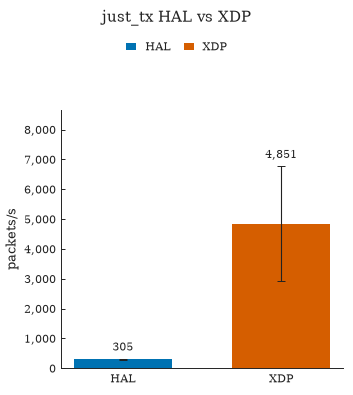


ADEV table (paper; not plotted):
variant       PPS    ADEV@1s                 95% CI   n
hal           305     11.22% (  9.14– 13.31)%   3
xdp          4851     24.12% (  9.01– 39.24)%   3


In [3]:
from collections import defaultdict

import matplotlib.pyplot as plt
from IPython.display import display

from utils.db import dsn_summary
from utils.experiment import (
    figure_tx_pps_mean,
    load_counter_samples,
    load_runs,
    mean_across_runs,
    mean_pps,
    mean_t_ci,
    overlapping_relative_adev,
    summarize_variant,
)

SOURCE_NOTE = "xpost-test just-tx-pps"

plt.ioff()
plt.close("all")
print(dsn_summary())

runs = load_runs(run_kind="pilot", source_note=SOURCE_NOTE)
assert len(runs), (
    "formal.experiment_runs 无 just-tx-pps pilot 行：先跑 ./xpost-test just-tx-pps"
)
samples = load_counter_samples(runs["run_id"].tolist())
print(f"runs={len(runs)} samples={len(samples)}")

by_variant = defaultdict(list)
adev_runs = defaultdict(list)

for _, row in runs.iterrows():
    sub = samples[samples["run_id"] == row["run_id"]].sort_values("time_ns")
    t_ns = sub["time_ns"].tolist()
    c = sub["counter_value"].tolist()
    variant = row["variant"]
    by_variant[variant].append(
        mean_pps(t_ns, c, run_id=row["run_id"], variant=variant, pair_id=int(row["pair_id"]))
    )
    adev = overlapping_relative_adev(t_ns, c)
    if adev:
        adev_runs[variant].append({tau: d["adev"] for tau, d in adev.items()})

summaries = {v: summarize_variant(rs) for v, rs in by_variant.items()}
adev_pool = {v: mean_across_runs(rows) for v, rows in adev_runs.items()}


def _at(pool, tau=1.0):
    row = pool.get(tau) or {}
    return row.get("mean"), (row.get("lo"), row.get("hi"))


for v, s in summaries.items():
    a_mean, (a_lo, a_hi) = _at(adev_pool.get(v, {}))
    print(
        f"{v}: valid={s['n_valid']}/{s['n_total']}  "
        f"PPS={s['mean_pps']:.0f}  ADEV@1s={100 * a_mean:.2f}% "
        f"({100 * a_lo:.2f}–{100 * a_hi:.2f})  "
        f"per-run={[round(x) for x in s['per_run_pps']]}"
    )

hal, xdp = summaries.get("hal", {}), summaries.get("xdp", {})
hal_pps = hal.get("per_run_pps") or []
xdp_pps = xdp.get("per_run_pps") or []
_, hal_pps_lo, hal_pps_hi = mean_t_ci(hal_pps)
_, xdp_pps_lo, xdp_pps_hi = mean_t_ci(xdp_pps)

fig, _ = figure_tx_pps_mean(
    hal_mean_pps=hal.get("mean_pps", float("nan")),
    xdp_mean_pps=xdp.get("mean_pps", float("nan")),
    hal_pps_ci=(hal_pps_lo, hal_pps_hi),
    xdp_pps_ci=(xdp_pps_lo, xdp_pps_hi),
    title="just_tx HAL vs XDP",
)
display(fig)
plt.close(fig)

print("\nADEV table (paper; not plotted):")
print(f"{'variant':8} {'PPS':>8} {'ADEV@1s':>10} {'95% CI':>22} {'n':>3}")
for v, s in summaries.items():
    a_mean, (a_lo, a_hi) = _at(adev_pool.get(v, {}))
    print(
        f"{v:8} {s['mean_pps']:8.0f} {100 * a_mean:9.2f}% "
        f"({100 * a_lo:6.2f}–{100 * a_hi:6.2f})% {s['n_valid']:3d}"
    )
